<a href="https://colab.research.google.com/github/danaschiopu/european-atfm-delay-analysis/blob/master/ATFM_delay_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# European airport ATFM delays – analysis and prediction

**Author:** Daniela Șchiopu

**Data:** EUROCONTROL Aviation Intelligence Unit – open data on airport arrival ATFM delays ([ansperformance.eu](https://ansperformance.eu/data/)), for period 2022-2024.

**Questions:**

*   RQ1. Which European airports generate the most arrival ATFM delay, and what are the main causes (weather, ATC capacity, staffing, aerodrome capacity…)?
*   RQ2. Can airports be grouped by their *delay-cause profile* (unsupervised learning)?
*   RQ3. Can we predict, one day ahead, whether an airport will have arrival ATFM delay (supervised learning)?

*ATFM = Air Traffic Flow Management. When demand exceeds capacity, the Network Manager delays flights on the ground; these delays are recorded per airport, per day and per cause.*

In [ ]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.inspection import permutation_importance

pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (10, 4)

## 1. Load the data
Files are downloaded directly from EUROCONTROL (one file per year).

The URL for download the files manually: https://ansperformance.eu/data/.

In [ ]:
YEARS = [2022, 2023, 2024]
URL = "https://www.eurocontrol.int/performance/data/download/csv/apt_dly_{year}.csv.bz2"

frames = []
for year in YEARS:
    try:
        frames.append(pd.read_csv(URL.format(year=year)))
        print(year, "loaded")
    except Exception as e:
        print(year, "FAILED:", e)

raw = pd.concat(frames, ignore_index=True)
print(raw.shape)
raw.head()

2022 loaded
2023 loaded
2024 loaded
(301044, 28)


,YEAR,MONTH_NUM,MONTH_MON,FLT_DATE,APT_ICAO,APT_NAME,STATE_NAME,FLT_ARR_1,DLY_APT_ARR_1,DLY_APT_ARR_A_1,DLY_APT_ARR_C_1,DLY_APT_ARR_D_1,DLY_APT_ARR_E_1,DLY_APT_ARR_G_1,DLY_APT_ARR_I_1,DLY_APT_ARR_M_1,DLY_APT_ARR_N_1,DLY_APT_ARR_O_1,DLY_APT_ARR_P_1,DLY_APT_ARR_R_1,DLY_APT_ARR_S_1,DLY_APT_ARR_T_1,DLY_APT_ARR_V_1,DLY_APT_ARR_W_1,DLY_APT_ARR_NA_1,FLT_ARR_1_DLY,FLT_ARR_1_DLY_15,ATFM_VERSION
0,2022,1,JAN,2022-01-01T00:00:00Z,EGBB,Birmingham,United Kingdom,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v2
1,2022,1,JAN,2022-01-01T00:00:00Z,LWSK,Skopje,North Macedonia,15,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v2
2,2022,1,JAN,2022-01-01T00:00:00Z,LFSB,Bâle-Mulhouse,France,72,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v2
3,2022,1,JAN,2022-01-01T00:00:00Z,EDDG,Muenster-Osnabrueck,Germany,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v2
4,2022,1,JAN,2022-01-01T00:00:00Z,EDDL,Dusseldorf,Germany,98,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,v2


## 2. Clean the data

In [ ]:
df = raw.copy()
df.columns = [c.strip().upper() for c in df.columns]        # make column names uniform
print(list(df.columns))

df["FLT_DATE"] = pd.to_datetime(df["FLT_DATE"], errors="coerce", utc=True).dt.tz_localize(None).dt.normalize()

cause_cols = [c for c in df.columns if re.fullmatch(r"DLY_APT_ARR_[A-Z]+_1", c)]
num_cols = ["FLT_ARR_1", "DLY_APT_ARR_1"] + cause_cols
df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

df = df.dropna(subset=["FLT_DATE"]).drop_duplicates(subset=["APT_ICAO", "FLT_DATE"])
df = df.sort_values(["APT_ICAO", "FLT_DATE"]).reset_index(drop=True)

CAUSES = {"A": "Accident/incident", "C": "ATC capacity", "D": "De-icing", "E": "Equipment (non-ATC)",
          "G": "Aerodrome capacity", "I": "Industrial action (ATC)", "M": "Airspace management",
          "N": "Industrial action (non-ATC)", "O": "Other", "P": "Special event", "R": "ATC routeing",
          "S": "ATC staffing", "T": "Equipment (ATC)", "V": "Environmental issues", "W": "Weather",
          "NA": "Not specified"}
cause_names = {c: CAUSES.get(c.split("_")[3], c) for c in cause_cols}

print(df.shape, "| airports:", df["APT_ICAO"].nunique(), "| period:", df["FLT_DATE"].min().date(), "->", df["FLT_DATE"].max().date())
df[num_cols].describe().T

['YEAR', 'MONTH_NUM', 'MONTH_MON', 'FLT_DATE', 'APT_ICAO', 'APT_NAME', 'STATE_NAME', 'FLT_ARR_1', 'DLY_APT_ARR_1', 'DLY_APT_ARR_A_1', 'DLY_APT_ARR_C_1', 'DLY_APT_ARR_D_1', 'DLY_APT_ARR_E_1', 'DLY_APT_ARR_G_1', 'DLY_APT_ARR_I_1', 'DLY_APT_ARR_M_1', 'DLY_APT_ARR_N_1', 'DLY_APT_ARR_O_1', 'DLY_APT_ARR_P_1', 'DLY_APT_ARR_R_1', 'DLY_APT_ARR_S_1', 'DLY_APT_ARR_T_1', 'DLY_APT_ARR_V_1', 'DLY_APT_ARR_W_1', 'DLY_APT_ARR_NA_1', 'FLT_ARR_1_DLY', 'FLT_ARR_1_DLY_15', 'ATFM_VERSION']
(301044, 28) | airports: 290 | period: 2022-01-01 -> 2024-12-31


,count,mean,std,min,25%,50%,75%,max
FLT_ARR_1,301044.0,76.247731,119.425382,0.0,7.0,26.0,92.0,818.0
DLY_APT_ARR_1,301044.0,58.190846,461.569553,0.0,0.0,0.0,0.0,30508.0
DLY_APT_ARR_A_1,301044.0,0.134313,16.330020,0.0,0.0,0.0,0.0,4725.0
DLY_APT_ARR_C_1,301044.0,8.263935,110.793546,0.0,0.0,0.0,0.0,8336.0
DLY_APT_ARR_D_1,301044.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0
DLY_APT_ARR_E_1,301044.0,0.276833,20.791156,0.0,0.0,0.0,0.0,6204.0
DLY_APT_ARR_G_1,301044.0,15.142856,195.945483,0.0,0.0,0.0,0.0,19766.0
DLY_APT_ARR_I_1,301044.0,0.919829,45.053463,0.0,0.0,0.0,0.0,9067.0
DLY_APT_ARR_M_1,301044.0,0.447901,21.402664,0.0,0.0,0.0,0.0,3824.0
DLY_APT_ARR_N_1,301044.0,0.127148,30.658678,0.0,0.0,0.0,0.0,10256.0


## 3. Exploratory analysis

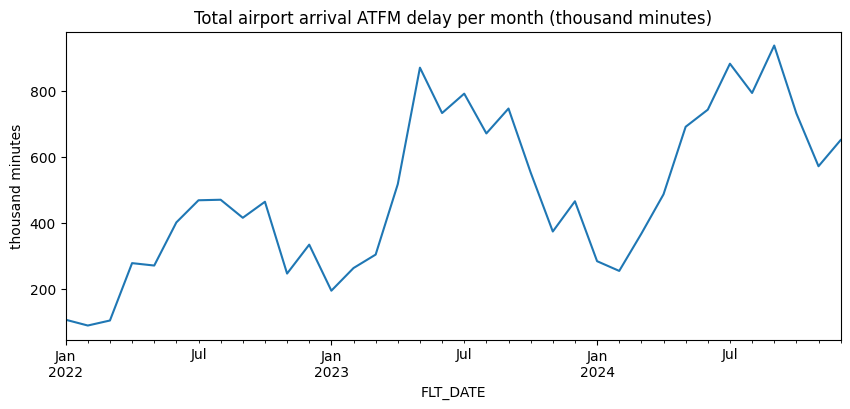

In [ ]:
# 3.1 Total arrival ATFM delay per month
monthly = df.set_index("FLT_DATE")["DLY_APT_ARR_1"].resample("MS").sum() / 1e3
monthly.plot(title="Total airport arrival ATFM delay per month (thousand minutes)")
plt.ylabel("thousand minutes"); plt.show()

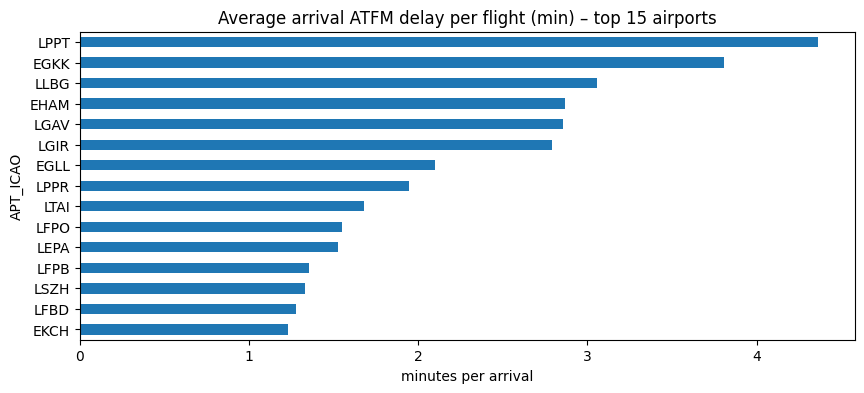

,name,arrivals,delay,delay_per_arrival
APT_ICAO,,,,
LPPT,Lisbon,329210,1436117.0,4.362313
EGKK,London/ Gatwick,370002,1407908.0,3.805136
LLBG,Tel Aviv,202224,618560.0,3.058786
EHAM,Amsterdam/ Schiphol,681472,1953052.0,2.865931
LGAV,Athens,354247,1010805.0,2.853390
LGIR,Heraklion,88672,247301.0,2.788941
EGLL,London/ Heathrow,656837,1377792.0,2.097616
LPPR,Porto,151778,294866.0,1.942745
LTAI,Antalya,319063,535957.0,1.679784


In [ ]:
# 3.2 Airports with the highest average delay per arrival
apt = df.groupby("APT_ICAO").agg(name=("APT_NAME", "first"), arrivals=("FLT_ARR_1", "sum"), delay=("DLY_APT_ARR_1", "sum"))
apt["delay_per_arrival"] = apt["delay"] / apt["arrivals"]
top = apt[apt["arrivals"] > 50_000].sort_values("delay_per_arrival", ascending=False).head(15)
top["delay_per_arrival"].sort_values().plot.barh(title="Average arrival ATFM delay per flight (min) – top 15 airports")
plt.xlabel("minutes per arrival"); plt.show()
top

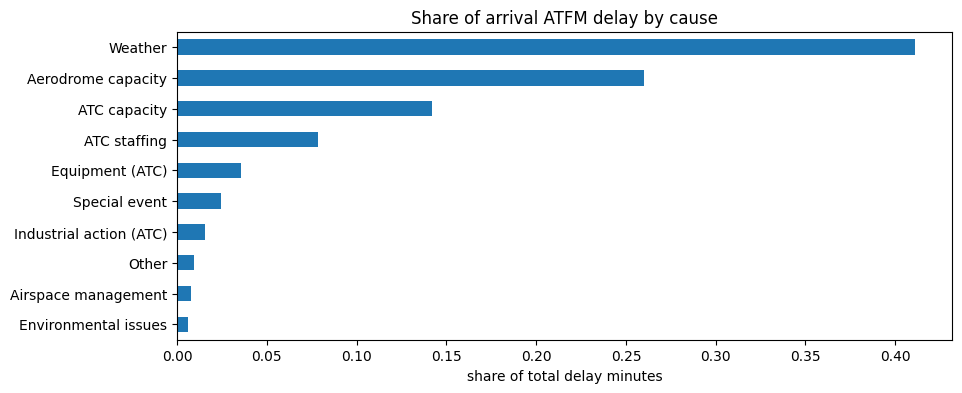

In [ ]:
# 3.3 Share of each delay cause
share = (df[cause_cols].sum() / df[cause_cols].sum().sum()).rename(index=cause_names).sort_values()
share[share > 0.005].plot.barh(title="Share of arrival ATFM delay by cause")
plt.xlabel("share of total delay minutes"); plt.show()

## 4. Unsupervised learning – clustering airports by delay-cause profile
Each airport is described by the share of its delay coming from each cause. K-means groups airports with similar profiles; PCA projects them to 2D for plotting.

In [ ]:
busy = apt[apt["arrivals"] > 20_000].index
prof = df[df["APT_ICAO"].isin(busy)].groupby("APT_ICAO")[cause_cols].sum()
prof = prof[prof.sum(axis=1) > 0]
prof = prof.div(prof.sum(axis=1), axis=0).rename(columns=cause_names)   # shares per airport

X_prof = StandardScaler().fit_transform(prof)
for k in range(2, 8):                                   # elbow method: inertia vs number of clusters
    print(k, round(KMeans(n_clusters=k, n_init=10, random_state=0).fit(X_prof).inertia_, 1))

2 1703.7
3 1557.2
4 1422.8
5 1280.9
6 1143.8
7 1032.2


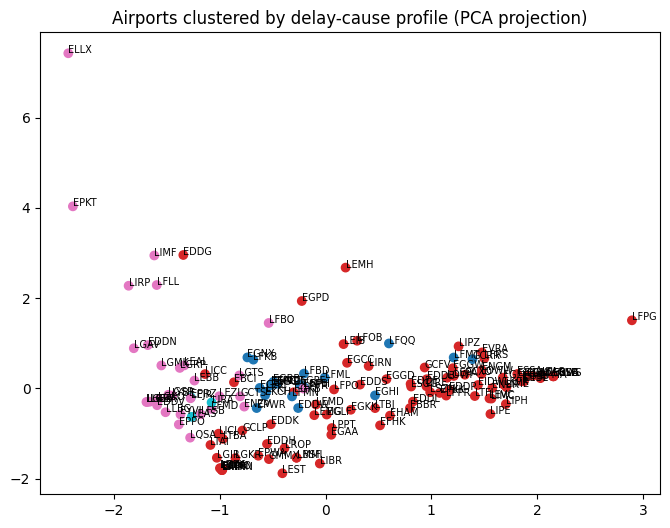

cluster,0,1,2,3
Accident/incident,0.02,0.02,0.01,0.00
ATC capacity,0.05,0.04,0.53,0.04
De-icing,0.00,0.00,0.00,0.00
Equipment (non-ATC),0.00,0.01,0.02,0.00
Aerodrome capacity,0.07,0.28,0.13,0.04
Industrial action (ATC),0.12,0.01,0.01,0.00
Airspace management,0.01,0.00,0.01,0.76
Industrial action (non-ATC),0.00,0.00,0.00,0.00
Other,0.01,0.04,0.03,0.09
Special event,0.02,0.07,0.02,0.07


In [ ]:
K = 4  # 4 clusters
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X_prof)
prof["cluster"] = km.labels_

xy = PCA(n_components=2).fit_transform(X_prof)
plt.figure(figsize=(8, 6))
plt.scatter(xy[:, 0], xy[:, 1], c=prof["cluster"], cmap="tab10")
for (x, y), name in zip(xy, prof.index):
    plt.annotate(name, (x, y), fontsize=7)
plt.title("Airports clustered by delay-cause profile (PCA projection)"); plt.show()

# Average profile of each cluster (e.g. "weather-driven", "ATC-capacity-driven")
prof.groupby("cluster").mean().T.round(2)

## 5. Supervised learning – will an airport have arrival ATFM delay tomorrow?
Target: `delayed` = 1 if the airport has any arrival ATFM delay that day.
Features use only information available the day before (yesterday's and last week's delay), plus calendar and traffic.
Validation is **time-based**: train on 2022–2023, and test on 2024.

In [ ]:
top_apts = apt.sort_values("arrivals", ascending=False).head(40).index
d = df[df["APT_ICAO"].isin(top_apts)].copy()

d["delayed"] = (d["DLY_APT_ARR_1"] > 0).astype(int)
d["dow"] = d["FLT_DATE"].dt.dayofweek
d["month"] = d["FLT_DATE"].dt.month
g = d.groupby("APT_ICAO")
d["delay_lag1"] = g["DLY_APT_ARR_1"].shift(1)  # yesterday's delay
d["delayed_lag1"] = g["delayed"].shift(1)
d["delay_roll7"] = g["DLY_APT_ARR_1"].transform(lambda s: s.shift(1).rolling(7).mean())
d["delayed_roll7"] = g["delayed"].transform(lambda s: s.shift(1).rolling(7).mean())
d["arr_lag1"] = g["FLT_ARR_1"].shift(1)
d = d.dropna(subset=["delay_lag1", "delay_roll7", "arr_lag1"])

print("Share of delayed airport-days:", round(d["delayed"].mean(), 3))

features_num = ["FLT_ARR_1", "arr_lag1", "delay_lag1", "delayed_lag1", "delay_roll7", "delayed_roll7"]
features_cat = ["APT_ICAO", "dow", "month"]
train = d[d["FLT_DATE"].dt.year <= 2023]
test = d[d["FLT_DATE"].dt.year == 2024]
X_tr, y_tr = train[features_num + features_cat], train["delayed"]
X_te, y_te = test[features_num + features_cat], test["delayed"]
print("train:", X_tr.shape, " test:", X_te.shape)

Share of delayed airport-days: 0.315
train: (28919, 9)  test: (14639, 9)


In [ ]:
prep = ColumnTransformer([("num", StandardScaler(), features_num),
                          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), features_cat)])
models = {
    "Logistic regression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "Random forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=0, class_weight="balanced"),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=0),
}

results, fitted = [], {}
# Baseline: "tomorrow will be like today"
results.append({"model": "Baseline (yesterday)", "ROC AUC": roc_auc_score(y_te, X_te["delayed_lag1"]),
                "F1": f1_score(y_te, X_te["delayed_lag1"])})
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)]).fit(X_tr, y_tr)
    proba = pipe.predict_proba(X_te)[:, 1]
    results.append({"model": name, "ROC AUC": roc_auc_score(y_te, proba), "F1": f1_score(y_te, proba > 0.5)})
    fitted[name] = pipe
pd.DataFrame(results).round(3)

,model,ROC AUC,F1
0,Baseline (yesterday),0.760,0.695
1,Logistic regression,0.874,0.736
2,Random forest,0.876,0.742
3,Gradient boosting,0.877,0.725


              precision    recall  f1-score   support

           0      0.824     0.906     0.863      9311
           1      0.801     0.662     0.725      5328

    accuracy                          0.817     14639
   macro avg      0.813     0.784     0.794     14639
weighted avg      0.816     0.817     0.813     14639



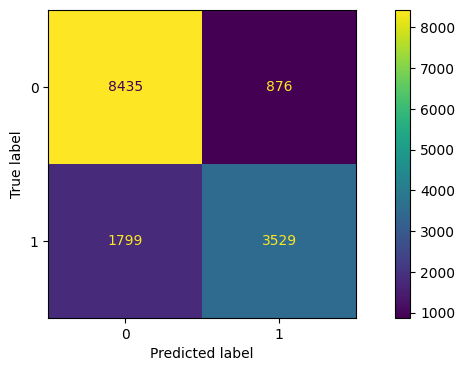

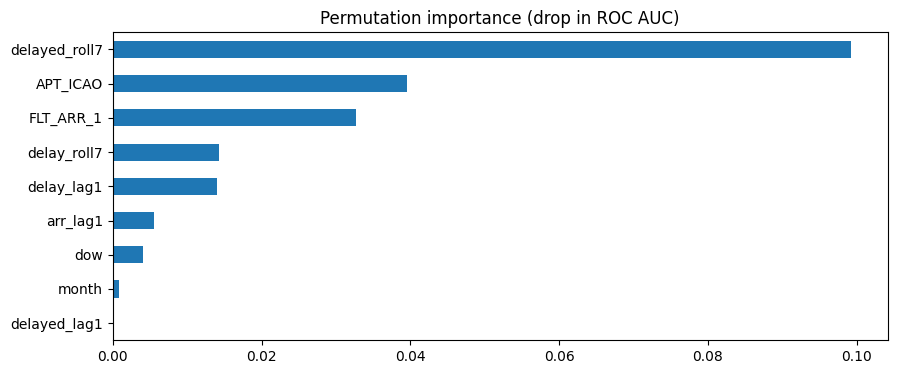

In [ ]:
best = fitted["Gradient boosting"]
print(classification_report(y_te, best.predict(X_te), digits=3))
ConfusionMatrixDisplay.from_estimator(best, X_te, y_te); plt.show()

imp = permutation_importance(best, X_te, y_te, n_repeats=5, random_state=0, scoring="roc_auc")
pd.Series(imp.importances_mean, index=X_te.columns).sort_values().plot.barh(title="Permutation importance (drop in ROC AUC)")
plt.show()

## 6. Conclusions

**Exploratory analysis (2022-2024)**

On average, an airport recorded 58.2 minutes of arrival ATFM delay per day. Weather is the main cause, at 23.9 minutes per day, or 41.1% of the total. It is followed by aerodrome capacity (15.1 minutes, 26.0%), ATC capacity (8.3 minutes, 14.2%) and ATC staffing (4.6 minutes, 7.9%). Together, these four causes account for almost 90% of all arrival ATFM delay. ATC equipment (3.6%) and special events (2.4%) come next, and every other cause stays below 2%. No delay was recorded for de-icing, ATC routeing or unspecified causes in this period.

Delay is highly concentrated: on more than 75% of airport-days there was no arrival ATFM delay at all, while the worst single day reached 30,508 minutes. Among airports with more than 50,000 arrivals, the highest average delay per arrival was at Lisbon (4.4 min), London Gatwick (3.8 min), Tel Aviv (3.1 min), Amsterdam Schiphol (2.9 min) and Athens (2.9 min). Most of these are busy airports operating close to their capacity.

---

**Clustering airports by delay-cause profile (k-means, k = 4)**

The elbow curve shows no clear break, so k = 4 was chosen because the four clusters are easy to interpret:

1. **Cluster 0**, staffing-driven: 61% ATC staffing and 12% ATC industrial action.
2. **Cluster 1**, weather and aerodrome capacity: 47% weather and 28% aerodrome capacity.
3. **Cluster 2**, ATC capacity and equipment: 53% ATC capacity and 15% ATC equipment.
4. **Cluster 3**, airspace management: 76% airspace management, a small group of airports affected mainly by airspace restrictions.

---

**Predicting next-day delay (supervised learning)**

The task was to predict whether an airport will have any arrival ATFM delay on a given day, using only information available the day before. With a time-based split (train 2022–2023, test 2024), all three machine learning models clearly beat the naive baseline (“tomorrow will be like today”): ROC AUC rises from 0.76 to about 0.87–0.88, and F1 from 0.70 to 0.73–0.74. The three models score almost the same (logistic regression 0.874, random forest 0.876, gradient boosting 0.877). Most of the predictive signal therefore comes from the features, mainly the airport’s recent delay history and traffic, and a simple, interpretable model such as logistic regression is enough for this task.


---

**Limitations and steps**

The analysis uses only airport-level historical data, with no weather forecasts, capacity plans or network-wide effects. A natural next step would be to add meteorological data (METAR (*Meteorological Aerodrome Report*) / TAF (*Terminal Aerodrome Forecast*)), since weather is the main cause of airport arrival ATFM delay.